# 2. Clasificación con Validación Cruzada k-Fold

**Materia:** Aprendizaje Automático (Machine Learning)
**Trabajo Práctico 2:** Clasificación Supervisada
**Dataset:** Bank Marketing (UCI / Kaggle)  
**Objetivo:** Entrenar y comparar los cuatro algoritmos requeridos (**Gaussian Naive Bayes, SVM, KNN y Random Forest**) con **validación cruzada estratificada ($k=5$)** sobre el conjunto de entrenamiento.

---

### Metodología:
1. **Elección del set de variables:** se comparan los 3 sets del notebook 1 con los 4 modelos y se elige el que obtiene mejor ROC-AUC de validación.
2. **Prevención de Data Leakage:** `StandardScaler` dentro de un `Pipeline`, ajustado solo con los folds de entrenamiento.
3. **Métricas:** **ROC-AUC** y **F1-score** de la clase minoritaria (`yes`).
4. **Diagnóstico de sobreajuste:** brecha de generalización (train − validación).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

RANDOM_STATE = 42
DATA_PATH = Path("../data")
FIGURES_PATH = Path("../figures")

## Sets de variables y preprocesamiento
- **Variables continuas:** `StandardScaler()` ajustado pliegue a pliegue.
- **Variables binarias (0/1):** `passthrough`.
- El test set no se utiliza en este cuaderno.

In [2]:
FEATURE_SETS = ["set1_high_capacity", "set2_core_decorrelated", "set3_minimalist_knn"]
SELECTED_SET = "set1_high_capacity"
BINARY_FEATURES = ["poutcome_success", "contact", "month_may", "month_mar", "month_oct"]


def load_train_set(set_name):
    train_data = pd.read_csv(DATA_PATH / f"ds_train_{set_name}.csv")
    return train_data.drop(columns="y"), train_data["y"]


def build_preprocessor(features):
    numerical_features = [feature for feature in features if feature not in BINARY_FEATURES]
    binary_features = [feature for feature in features if feature in BINARY_FEATURES]
    return ColumnTransformer([
        ("numerical", StandardScaler(), numerical_features),
        ("binary", "passthrough", binary_features),
    ])

## Clasificadores (hiperparámetros por defecto)
`class_weight="balanced"` en SVM y Random Forest para compensar el desbalance de clases (11% yes).

In [3]:
classifiers = {
    "Naive Bayes": GaussianNB(),
    "SVM": SVC(class_weight="balanced", random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(),
    "Random Forest": RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE),
}

## Elección y Justificación de Métricas
- **ROC-AUC:** Evalúa la capacidad de ordenar a los clientes para cualquier umbral; no se ve afectada por el desbalance de clases.
- **F1 (clase 'yes'):** Media armónica entre precisión y recall de la clase minoritaria; accuracy es engañosa (88.7% prediciendo siempre 'no').

In [4]:
SCORING_METRICS = ["roc_auc", "f1"]

## Validación cruzada estratificada (5 folds · Conjunto de Train) para cada modelo y cada set
Los tres sets tienen las mismas filas en el mismo orden, por lo que los 5 folds son idénticos en todas las combinaciones.

In [5]:
stratified_kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_results = []
for set_name in FEATURE_SETS:
    X_train, y_train = load_train_set(set_name)
    for classifier_name, classifier in classifiers.items():
        classification_pipeline = Pipeline([
            ("preprocessing", build_preprocessor(X_train.columns)),
            ("classifier", classifier),
        ])
        fold_scores = cross_validate(
            classification_pipeline, X_train, y_train,
            cv=stratified_kfold,
            scoring=SCORING_METRICS,
            return_train_score=True,
            n_jobs=-1,
        )
        for metric in SCORING_METRICS:
            cv_results.append({
                "set": set_name,
                "classifier": classifier_name,
                "metric": metric,
                "train_mean": fold_scores[f"train_{metric}"].mean(),
                "validation_mean": fold_scores[f"test_{metric}"].mean(),
                "validation_std": fold_scores[f"test_{metric}"].std(),
            })
    print(f"{set_name}: completado")

cv_results = pd.DataFrame(cv_results)

set1_high_capacity: completado


set2_core_decorrelated: completado


set3_minimalist_knn: completado


## Comparación de sets: ROC-AUC de validación

In [6]:
set_comparison = cv_results[cv_results["metric"] == "roc_auc"].pivot(
    index="classifier", columns="set", values="validation_mean")
set_comparison.round(3)

set,set1_high_capacity,set2_core_decorrelated,set3_minimalist_knn
classifier,,,
KNN,0.726,0.725,0.714
Naive Bayes,0.777,0.752,0.767
Random Forest,0.725,0.721,0.708
SVM,0.766,0.764,0.753


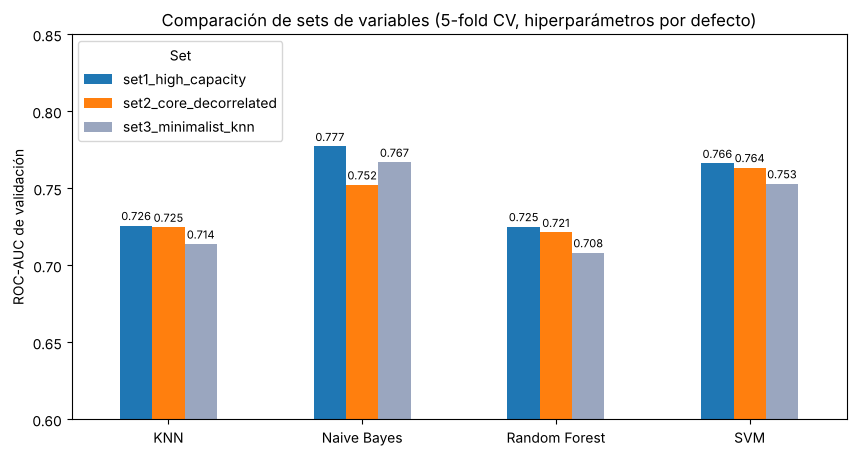

In [7]:
ax = set_comparison.plot(kind="bar", figsize=(10, 5), rot=0, color=["#1f77b4", "#ff7f0e", "#9AA6BF"])
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.3f", padding=2, fontsize=8)
ax.set_ylim(0.6, 0.85)
ax.set_xlabel("")
ax.set_ylabel("ROC-AUC de validación")
ax.set_title("Comparación de sets de variables (5-fold CV, hiperparámetros por defecto)")
ax.legend(title="Set", loc="upper left")
plt.savefig(FIGURES_PATH / "07_feature_set_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

**Decisión:** el **set 1** obtiene igual o mejor ROC-AUC que los sets 2 y 3 en los 4 modelos (Naive Bayes 0.777 vs. 0.752 / 0.767; SVM 0.766 vs. 0.764 / 0.753; KNN 0.726 vs. 0.725 / 0.714; Random Forest 0.725 vs. 0.721 / 0.708). Se usa el **set 1 para todos los modelos** en los pasos siguientes: la justificación teórica del set 2 (eliminar la colinealidad) no se traduce en mejor desempeño.

## Resultados de validación cruzada con el set elegido

In [8]:
selected_results = cv_results[cv_results["set"] == SELECTED_SET].drop(columns="set")
selected_results.round(3)

,classifier,metric,train_mean,validation_mean,validation_std
0,Naive Bayes,roc_auc,0.777,0.777,0.008
1,Naive Bayes,f1,0.422,0.421,0.016
2,SVM,roc_auc,0.780,0.766,0.013
3,SVM,f1,0.469,0.466,0.012
4,KNN,roc_auc,0.867,0.726,0.009
5,KNN,f1,0.498,0.382,0.015
6,Random Forest,roc_auc,0.957,0.725,0.013
7,Random Forest,f1,0.581,0.341,0.012


## Comparación de clasificadores (Media ± Desvío en los 5 folds de validación)

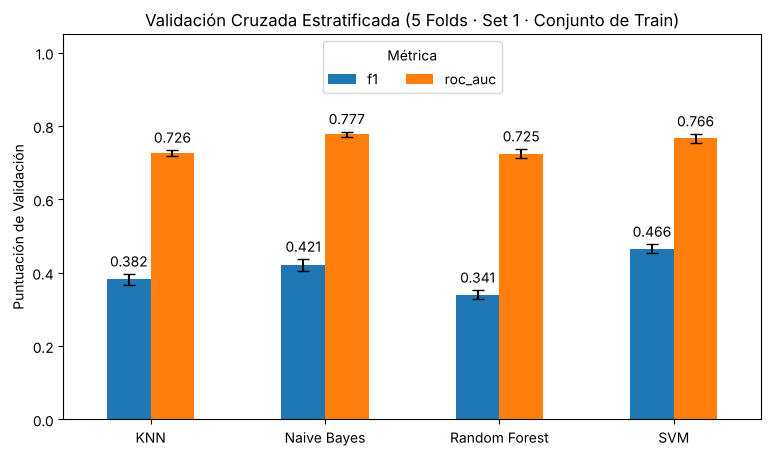

In [9]:
validation_means = selected_results.pivot(index="classifier", columns="metric", values="validation_mean")
validation_stds = selected_results.pivot(index="classifier", columns="metric", values="validation_std")

ax = validation_means.plot(kind="bar", yerr=validation_stds, capsize=4, figsize=(9, 5), rot=0)
for bars in ax.containers:
    if hasattr(bars, "patches"):
        ax.bar_label(bars, fmt="%.3f", padding=3)
ax.set_ylim(0, 1.05)
ax.legend(title="Métrica", loc="upper center", ncols=2)
ax.set_xlabel("")
ax.set_ylabel("Puntuación de Validación")
ax.set_title("Validación Cruzada Estratificada (5 Folds · Set 1 · Conjunto de Train)")
plt.savefig(FIGURES_PATH / "08_cv_classifier_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

## Brecha de generalización (Train − Validación)
Diagnóstico de sobreajuste: discrepancias grandes entre el desempeño en entrenamiento y validación evidencian memorización de ruido.

In [10]:
selected_results["generalization_gap"] = selected_results["train_mean"] - selected_results["validation_mean"]
selected_results.pivot(index="classifier", columns="metric", values="generalization_gap").round(3)

metric,f1,roc_auc
classifier,,
KNN,0.116,0.141
Naive Bayes,0.000,0.000
Random Forest,0.240,0.232
SVM,0.003,0.014


## Conclusiones del Paso 2
- Con el set 1 y valores por defecto, **Naive Bayes** (ROC-AUC 0.777) y **SVM** (0.766, mejor F1: 0.466) son los mejores y casi no tienen brecha.
- **Random Forest** (0.957 train vs. 0.725 validación) y **KNN** (0.867 vs. 0.726) sobreajustan con sus valores por defecto (árboles sin límite de profundidad; k = 5).
- En el **Paso 3** se ajustan los hiperparámetros con curvas de validación.